# Reproducibility of the full pipeline: letting agent fees, five end-to-end runs

The live pipeline (`web_app/analyse.py`, `run_analysis`) was run **five times from scratch** on one document, with
every LLM step repeated: sentence extraction (Sonnet), core-theme finding (Sonnet), grouping around the core themes (Haiku)
and scoring (Sonnet). Each run is on its own copy of `documents/letting_agent_fees` (`letting_agent_fees_rep1` to `_rep5`)
and writes to `results/letting_agent_fees_rep{1..5}/`.

This extends `agreement_analysis.ipynb` (extraction self-consistency on state pension, sections 5-8) and
`scoring_reproducibility.ipynb` (scoring noise, fixed and varying extraction), which looked at the steps one at a time. Here all steps
vary together, and the new core-theme step is included. The document was chosen as the highest-rated small document in the
2018 comparison (547 sentences; 2018 scored it 2/2/2/2; the earlier single run used in the 2018 comparison, from a separate experiment script, scored 2/2/1/0).

1. **Extraction**: overlap in the sentences each run assigns to each aspect (Cohen's and Fleiss' kappa, per-sentence stability).
2. **Core themes**: how much the named core themes and their sentences move between runs.
3. **Scores**: how much the four aspect scores and the total move, set against the earlier fixed-extraction repeats.
4. **Cost and time.**

Everything is read from persisted artefacts; no LLM calls are made here.

In [1]:
import os, json, re
from itertools import combinations
from collections import Counter
from pathlib import Path

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import cohen_kappa_score

warnings.filterwarnings("ignore")   # kappa is undefined (NaN) for an aspect no run extracted anything for; that is reported, not an error

pd.set_option("display.max_colwidth", 110)
RESULTS, DOCUMENTS = Path("../results"), Path("../documents")
DOC = "letting_agent_fees"
ASPECTS = ["diagnosis", "proposal", "implementation", "testing"]
CORE_ASPECTS = ["diagnosis", "proposal", "implementation"]
SCORE_2018 = {"diagnosis": 2, "proposal": 2, "implementation": 2, "testing": 2}

lines = [l for l in (DOCUMENTS / DOC / "input.txt").read_text().splitlines() if l.strip()]
SENT_IDS = [l.split()[0] for l in lines]
SENT_TEXT = {l.split()[0]: l.split(" ", 1)[1] if " " in l else "" for l in lines}

run_dirs = [RESULTS / f"{DOC}_rep{i}" for i in range(1, 6)]
complete = [d for d in run_dirs if all((d / a / "scoring.json").exists() for a in ASPECTS)]
if os.environ.get("NB_TEST"):                       # development only: add the original (older) run to exercise the code
    complete = complete + [RESULTS / DOC]
RUNS = {f"run{i+1}": d for i, d in enumerate(complete)}
N_RUNS = len(RUNS)
print(f"{len(SENT_IDS)} sentences; {N_RUNS} complete runs: {list(RUNS)}")
assert N_RUNS >= 2, "need at least two complete runs"

ink, grid = "#0b0b0b", "#e1e0d9"
aspect_colors = {"diagnosis": "#2a78d6", "proposal": "#eb6834", "implementation": "#1baf7a", "testing": "#eda100"}
blue_ramp = ["#cde2fb", "#9ec5f4", "#5598e7", "#2a78d6", "#1c5cab", "#0d366b"]

def style(ax, ygrid=True):
    ax.tick_params(colors=ink)
    for s in ["top", "right"]: ax.spines[s].set_visible(False)
    for s in ["left", "bottom"]: ax.spines[s].set_color(grid)
    if ygrid: ax.yaxis.grid(True, color=grid, linewidth=0.8); ax.set_axisbelow(True)

def fleiss_kappa(counts):
    """counts[i, j] = number of raters putting item i in category j."""
    n_items = counts.shape[0]; n = counts.sum(axis=1)[0]
    p_i = (np.square(counts).sum(axis=1) - n) / (n * (n - 1))
    p_j = counts.sum(axis=0) / (n_items * n)
    pe = np.square(p_j).sum()
    return np.nan if pe == 1 else (p_i.mean() - pe) / (1 - pe)

547 sentences; 5 complete runs: ['run1', 'run2', 'run3', 'run4', 'run5']


## 1. Sentence extraction

`call_llm_extract_lines` assigns each sentence to diagnosis, proposal, implementation, testing or none. As in
`agreement_analysis.ipynb` sections 5-6, each aspect is treated as a Yes/No call per sentence and the five runs are compared with
pairwise percent agreement and Cohen's kappa (all run pairs), Fleiss' kappa across runs, and per-sentence stability.

In [2]:
def aspect_ids(d, aspect):
    p = d / aspect / "lines.txt"
    return set(l.split()[0] for l in p.read_text().splitlines() if l.strip()) if p.exists() else set()

calls = {a: pd.DataFrame({r: pd.Series(SENT_IDS).isin(aspect_ids(d, a)).values for r, d in RUNS.items()}, index=SENT_IDS)
         for a in ASPECTS}

def variability(runs_df):
    pcts, kappas = [], []
    for a, b in combinations(runs_df.columns, 2):
        pcts.append((runs_df[a] == runs_df[b]).mean()); kappas.append(cohen_kappa_score(runs_df[a], runs_df[b]))
    yes = runs_df.sum(axis=1)
    fleiss = fleiss_kappa(np.column_stack([N_RUNS - yes, yes]))
    stable = (yes == 0) | (yes == N_RUNS)
    return {"flagged per run": runs_df.sum().tolist(), "mean pairwise %": np.mean(pcts), "mean pairwise kappa": np.mean(kappas),
            "min kappa": min(kappas), "max kappa": max(kappas), "Fleiss kappa": fleiss,
            "stable in all runs": stable.sum(), "% stable": stable.mean(), "yes_counts": yes,
            "flagged by any": int((yes > 0).sum()), "flagged by all": int((yes == N_RUNS).sum())}

var = {a: variability(calls[a]) for a in ASPECTS}
tab = pd.DataFrame({a: {k: (round(v, 3) if isinstance(v, float) else v) for k, v in var[a].items() if k != "yes_counts"} for a in ASPECTS}).T
tab

,flagged per run,mean pairwise %,mean pairwise kappa,min kappa,max kappa,Fleiss kappa,stable in all runs,% stable,flagged by any,flagged by all
diagnosis,"[188, 109, 91, 92, 234]",0.851,0.644,0.421,0.928,0.613,397,0.726,234,84
proposal,"[72, 58, 90, 60, 76]",0.939,0.731,0.609,0.88,0.729,479,0.876,115,47
implementation,"[112, 117, 68, 74, 71]",0.932,0.754,0.604,0.919,0.748,476,0.87,129,58
testing,"[0, 0, 0, 0, 0]",1.0,NaN,NaN,NaN,NaN,547,1.0,0,0


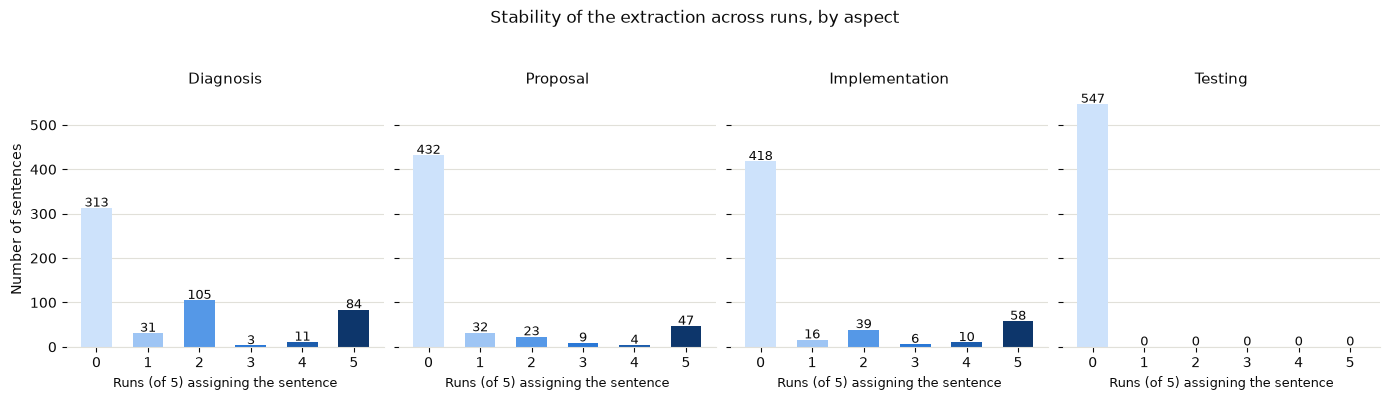

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.8), sharey=True)
for ax, a in zip(axes, ASPECTS):
    h = var[a]["yes_counts"].value_counts().reindex(range(N_RUNS + 1), fill_value=0)
    bars = ax.bar(h.index.astype(str), h.values, color=blue_ramp[:N_RUNS + 1] if N_RUNS == 5 else blue_ramp[1:N_RUNS + 2], width=0.6)
    for b, v in zip(bars, h.values): ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 3, str(v), ha="center", color=ink, fontsize=9)
    ax.set_title(a.capitalize(), color=ink, fontsize=11); ax.set_xlabel(f"Runs (of {N_RUNS}) assigning the sentence", color=ink, fontsize=9)
    style(ax); ax.spines["left"].set_visible(False)
axes[0].set_ylabel("Number of sentences", color=ink)
fig.suptitle("Stability of the extraction across runs, by aspect", color=ink, y=1.04); fig.tight_layout(); plt.show()

### Reference: the same measures on state pension (new prompt, five runs, `agreement_analysis.ipynb` section 8)

Fleiss' kappa 0.90 / 0.79 / 0.73 / 0.81 and 92% / 80% / 85% / 94% of sentences stable, for diagnosis / proposal / implementation /
testing (417 sentences). Those runs held everything but the extraction call fixed; the numbers above are from the complete
pipeline, but the extraction step is the same call, so the two are comparable.

In [4]:
ref = pd.DataFrame({"state pension Fleiss kappa": [0.900, 0.793, 0.728, 0.806], "state pension % stable": [91.8, 80.3, 84.9, 94.0]},
                   index=ASPECTS)
ref["letting agents Fleiss kappa"] = [round(var[a]["Fleiss kappa"], 3) for a in ASPECTS]
ref["letting agents % stable"] = [round(100 * var[a]["% stable"], 1) for a in ASPECTS]
ref

,state pension Fleiss kappa,state pension % stable,letting agents Fleiss kappa,letting agents % stable
diagnosis,0.900,91.8,0.613,72.6
proposal,0.793,80.3,0.729,87.6
implementation,0.728,84.9,0.748,87.0
testing,0.806,94.0,NaN,100.0


### Was a single run representative?

Each run against the majority vote of all runs (an assignment made by at least half the runs), per aspect: Cohen's kappa.

The last two columns are the mean and the sample standard deviation of the five kappas for that aspect: a high mean with a small SD means any single run is a good stand-in for the majority; a large SD means some runs are far from it.

In [5]:
rows = []
for a in ASPECTS:
    maj = calls[a].sum(axis=1) * 2 >= N_RUNS
    row = {"aspect": a, "majority flags": int(maj.sum())}
    ks = {r: cohen_kappa_score(calls[a][r], maj) for r in RUNS}
    for r, k in ks.items(): row[r] = round(k, 3)
    row["mean"] = round(pd.Series(ks).mean(), 3)
    row["SD"] = round(pd.Series(ks).std(), 3)          # sample SD (n - 1) across the runs
    rows.append(row)
pd.DataFrame(rows).set_index("aspect")

,majority flags,run1,run2,run3,run4,run5,mean,SD
aspect,,,,,,,,
diagnosis,98,0.570,0.911,0.955,0.962,0.452,0.770,0.241
proposal,60,0.880,0.848,0.770,1.000,0.665,0.832,0.125
implementation,74,0.679,0.730,0.919,1.000,0.897,0.845,0.135
testing,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### All four categories together

One label per sentence per run (diagnosis, proposal, implementation, testing, none, or `multi` if the run put the sentence in more than one
aspect). Pairwise Cohen's kappa and Fleiss' kappa over these categories, and where the disagreements sit.

In [6]:
def label(sid, run):
    got = [a for a in ASPECTS if calls[a].loc[sid, run]]
    return got[0] if len(got) == 1 else ("none" if not got else "multi")

labels = pd.DataFrame({r: [label(s, r) for s in SENT_IDS] for r in RUNS}, index=SENT_IDS)
print("sentences in more than one aspect, per run:", (labels == "multi").sum().to_dict())
arr = np.eye(N_RUNS)
for (i, a), (j, b) in combinations(list(enumerate(RUNS)), 2):
    arr[i, j] = arr[j, i] = cohen_kappa_score(labels[a], labels[b])
pw = pd.DataFrame(arr, index=list(RUNS), columns=list(RUNS))
cats = [c for c in ASPECTS + ["none", "multi"] if (labels == c).any().any()]
counts = np.column_stack([(labels == c).sum(axis=1) for c in cats])
off = pw.values[np.triu_indices(N_RUNS, 1)]
print(f"Cohen's kappa over {len(cats)} categories, all {len(off)} run pairs: mean {off.mean():.3f} (range {off.min():.3f}-{off.max():.3f})")
print(f"Fleiss' kappa over the {N_RUNS} runs: {fleiss_kappa(counts):.3f}")
print(f"Sentences given the same label by every run: {(labels.nunique(axis=1) == 1).sum()}/{len(labels)} ({(labels.nunique(axis=1) == 1).mean():.1%})")
display(pw.round(3))

flow = Counter()
for sid in SENT_IDS:
    for x, y in combinations(sorted(labels.loc[sid]), 2):
        if x != y: flow[(x, y)] += 1
pd.DataFrame([{"labels in conflict": f"{x} vs {y}", "run-pair disagreements": n} for (x, y), n in flow.most_common()]).set_index("labels in conflict")

sentences in more than one aspect, per run: {'run1': 0, 'run2': 0, 'run3': 0, 'run4': 0, 'run5': 0}
Cohen's kappa over 4 categories, all 10 run pairs: mean 0.685 (range 0.554-0.879)
Fleiss' kappa over the 5 runs: 0.677
Sentences given the same label by every run: 354/547 (64.7%)


,run1,run2,run3,run4,run5
run1,1.000,0.672,0.605,0.600,0.784
run2,0.672,1.000,0.765,0.804,0.605
run3,0.605,0.765,1.000,0.879,0.586
run4,0.600,0.804,0.879,1.000,0.554
run5,0.784,0.605,0.586,0.554,1.000


,run-pair disagreements
labels in conflict,
diagnosis vs none,665
implementation vs proposal,159
implementation vs none,157
diagnosis vs proposal,93
none vs proposal,84
diagnosis vs implementation,58


In [7]:
rows = []
for sid in SENT_IDS:
    labs = labels.loc[sid]
    if labs.nunique() > 1:
        rows.append({"sentence": sid, "distinct labels": labs.nunique(), **labs.to_dict(), "text": SENT_TEXT[sid][:130]})
unstable = pd.DataFrame(rows).sort_values(["distinct labels", "sentence"], ascending=[False, True])
print(f"{len(unstable)} of {len(SENT_IDS)} sentences get different labels in different runs")
unstable.head(15).set_index("sentence")

193 of 547 sentences get different labels in different runs


,distinct labels,run1,run2,run3,run4,run5,text
sentence,,,,,,,
S0037,3,diagnosis,none,proposal,none,diagnosis,Transparency requirements were implemented by the Consumer Rights Act 2015.
S0038,3,diagnosis,none,proposal,none,diagnosis,"They require letting agents to publicise a full tariff of their fees, to make clear whether or not they ar..."
S0039,3,diagnosis,none,proposal,none,diagnosis,"A fine of up to £5,000 can be levied against agents who fail to comply."
S0063,3,diagnosis,proposal,none,none,diagnosis,The fees that letting agents charge are currently not regulated in either Wales or Northern Ireland but th...
S0191,3,diagnosis,none,proposal,none,diagnosis,The Government encourages trading standards to use their powers to take robust action against any letting ...
S0316,3,proposal,none,implementation,none,implementation,"As is the case now, agents and landlords should not discriminate against individuals when considering pote..."
S0320,3,proposal,diagnosis,implementation,diagnosis,diagnosis,It is worth noting that where discriminatory practices do occur this is often during the advertisement of ...
S0322,3,proposal,none,none,none,diagnosis,The current law is clear that agents and landlords must not advertise or let a property in a way that unla...
S0390,3,implementation,implementation,proposal,none,proposal,The government recognises the appetite for wider regulation of the sector in order to combat the minority ...


## 2. Core themes

For diagnosis, proposal and implementation, `find_core` names two to four core themes from the whole document; the grouping step then
assigns each sentence in the aspect to a theme, and a section's score is the mean of the core themes' levels. Testing is scored as one
block and has no core themes. Two things can move between runs: *which themes are named*, and *which sentences end up in them*.

In [8]:
def core_names(d, a):
    p = d / "core_themes.json"
    return [t["name"] for t in json.loads(p.read_text())[a]["core_themes"]] if p.exists() else []

def core_ids(d, a):
    w = d / a / "weights.json"; c = d / a / "classification.json"
    if not (w.exists() and c.exists()): return set()
    core = {t["theme"] for t in json.loads(w.read_text())["themes"] if t["weight"] == "core"}
    return {i for t in json.loads(c.read_text())["themes"] if t["name"] in core for i in t["ids"]}

names = pd.DataFrame({a: {r: " | ".join(core_names(d, a)) for r, d in RUNS.items()} for a in CORE_ASPECTS})
display(pd.DataFrame({a: {r: len(core_names(d, a)) for r, d in RUNS.items()} for a in CORE_ASPECTS}).assign().rename_axis("core themes named"))
names

,diagnosis,proposal,implementation
core themes named,,,
run1,4,4,4
run2,4,4,4
run3,4,4,4
run4,3,4,4
run5,4,4,4


,diagnosis,proposal,implementation
run1,"High, opaque and variable tenant fees | Principal-agent market failure | Existing regulation has not fixed...",Rebalancing market power through a fee ban | Scottish precedent as the evidence base | Scope and design of...,Local authority (Trading Standards) enforcement | Tenant empowerment and education | Additional enforcemen...
run2,High and opaque tenant fees | Market failure from misaligned incentives | Existing transparency regulation...,Rebalancing market power toward landlords | Scope and design of the ban | Scottish precedent as supporting...,Local authority enforcement via Trading Standards | Additional enforcement infrastructure | Tenant empower...
run3,Scale and variability of tenant fees | Weak tenant market power and misaligned incentives | Failure of exi...,Banning fees to rebalance market power | Scope and exceptions of the ban | Scottish precedent as supportin...,Local authority (Trading Standards) enforcement | Potential lead enforcement authority | Tenant empowermen...
run4,High and opaque tenant fees | Tenants' lack of market power | Financial harm to tenants,Rebalancing market power through a fee ban | Scottish precedent as supporting evidence | Assessing the ren...,"Local enforcement via Trading Standards, strengthened by new mechanisms | Penalties for non-compliance | T..."
run5,High and opaque tenant fees | Weak tenant market power | Failure of existing transparency regulation | Fin...,Shifting costs to the landlord market | Benefits to tenants from a clear ban | Comprehensive scope to prev...,Local authority enforcement | Strengthened enforcement architecture | Tenant empowerment and education | D...


In [9]:
core = {a: {r: core_ids(d, a) for r, d in RUNS.items()} for a in CORE_ASPECTS}
rows, core_var = [], {}
for a in CORE_ASPECTS:
    sets = core[a]; jac = [len(sets[x] & sets[y]) / max(len(sets[x] | sets[y]), 1) for x, y in combinations(RUNS, 2)]
    cdf = pd.DataFrame({r: pd.Series(SENT_IDS).isin(s).values for r, s in sets.items()}, index=SENT_IDS)
    yes = cdf.sum(axis=1); k = [cohen_kappa_score(cdf[x], cdf[y]) for x, y in combinations(RUNS, 2)]
    core_var[a] = yes
    rows.append({"aspect": a, "core sentences per run": [len(s) for s in sets.values()],
                 "in any run": int((yes > 0).sum()), "in every run": int((yes == N_RUNS).sum()),
                 "mean pairwise Jaccard": round(np.mean(jac), 3), "min Jaccard": round(min(jac), 3),
                 "mean pairwise kappa": round(np.mean(k), 3), "Fleiss kappa": round(fleiss_kappa(np.column_stack([N_RUNS - yes, yes])), 3)})
pd.DataFrame(rows).set_index("aspect")

,core sentences per run,in any run,in every run,mean pairwise Jaccard,min Jaccard,mean pairwise kappa,Fleiss kappa
aspect,,,,,,,
diagnosis,"[60, 72, 60, 54, 71]",83,44,0.735,0.617,0.825,0.825
proposal,"[39, 52, 40, 37, 39]",58,24,0.668,0.571,0.783,0.783
implementation,"[54, 98, 45, 64, 55]",117,37,0.579,0.330,0.686,0.667


Jaccard overlap is the size of the intersection over the size of the union of two runs' core sentence sets; kappa is over all sentences
in the document (core or not), so it is higher than Jaccard when most sentences are never core. The state pension / letting agents
comparisons in `TODO.md` quote a median core-sentence overlap of about 75% between runs for this design on other documents.

## 3. Scores

Each aspect's score is the mean of its core themes' levels, rounded (exact halves down); Testing is scored as one block.

In [10]:
rows = []
for r, d in RUNS.items():
    for a in ASPECTS:
        s = json.loads((d / a / "scoring.json").read_text())
        rows.append({"aspect": a, "run": r, "score": s["score"], "core_mean": s.get("core_mean"), "reasoning": s["reasoning"]})
scores = pd.DataFrame(rows)
wide = scores.pivot(index="run", columns="aspect", values="score")[ASPECTS]
wide["total"] = wide.sum(axis=1)
display(wide)
summ = scores.groupby("aspect")["score"].agg(scores_seen=lambda s: sorted(s.unique().tolist()), n_unique="nunique", min="min", max="max", mean="mean", std="std").reindex(ASPECTS)
summ["same in every run"] = summ["n_unique"] == 1
summ["modal score"] = [scores[scores.aspect == a]["score"].mode().iloc[0] for a in ASPECTS]
summ["runs at modal score"] = [int((scores[scores.aspect == a]["score"] == m).sum()) for a, m in zip(ASPECTS, summ["modal score"])]
summ["2018"] = [SCORE_2018[a] for a in ASPECTS]
print(summ.round(2).to_string())
t = wide["total"]
print(f"\n{int(summ['same in every run'].sum())}/{len(ASPECTS)} aspects gave the same score in all {N_RUNS} runs.")
print(f"Total score (out of 12): mean {t.mean():.2f}, SD {t.std():.2f}, range {t.min()}-{t.max()}; 2018 total {sum(SCORE_2018.values())}")

aspect,diagnosis,proposal,implementation,testing,total
run,,,,,
run1,2,1,1,0,4
run2,2,1,1,0,4
run3,1,1,1,0,3
run4,2,1,1,0,4
run5,2,2,0,0,4


               scores_seen  n_unique  min  max  mean   std  same in every run  modal score  runs at modal score  2018
aspect                                                                                                               
diagnosis           [1, 2]         2    1    2   1.8  0.45              False            2                    4     2
proposal            [1, 2]         2    1    2   1.2  0.45              False            1                    4     2
implementation      [0, 1]         2    0    1   0.8  0.45              False            1                    4     2
testing                [0]         1    0    0   0.0  0.00               True            0                    5     2

1/4 aspects gave the same score in all 5 runs.
Total score (out of 12): mean 3.80, SD 0.45, range 3-4; 2018 total 8


In [11]:
pairs = list(combinations(RUNS, 2))
exact = np.mean([wide.loc[x, a] == wide.loc[y, a] for x, y in pairs for a in ASPECTS])
within1 = np.mean([abs(wide.loc[x, a] - wide.loc[y, a]) <= 1 for x, y in pairs for a in ASPECTS])
tot_exact = np.mean([wide.loc[x, "total"] == wide.loc[y, "total"] for x, y in pairs])
tot_within1 = np.mean([abs(wide.loc[x, "total"] - wide.loc[y, "total"]) <= 1 for x, y in pairs])
# ICC(1,1): aspects as subjects, runs as repeated measurements of the same subject
X = wide[ASPECTS].T.values.astype(float); n, k = X.shape
msb = k * ((X.mean(1) - X.mean()) ** 2).sum() / (n - 1)
msw = ((X - X.mean(1, keepdims=True)) ** 2).sum() / (n * (k - 1))
icc = (msb - msw) / (msb + (k - 1) * msw) if (msb + (k - 1) * msw) else np.nan
print(f"Across all {len(pairs)} run pairs and 4 aspects: identical aspect score {exact:.0%}, within one level {within1:.0%}")
print(f"Across run pairs, identical total {tot_exact:.0%}, totals within one point {tot_within1:.0%}")
print(f"ICC(1,1), aspects as subjects, runs as repeats: {icc:.2f} (how much of the variation in scores is between aspects, not between runs)")

Across all 10 run pairs and 4 aspects: identical aspect score 70%, within one level 100%
Across run pairs, identical total 60%, totals within one point 100%
ICC(1,1), aspects as subjects, runs as repeats: 0.78 (how much of the variation in scores is between aspects, not between runs)


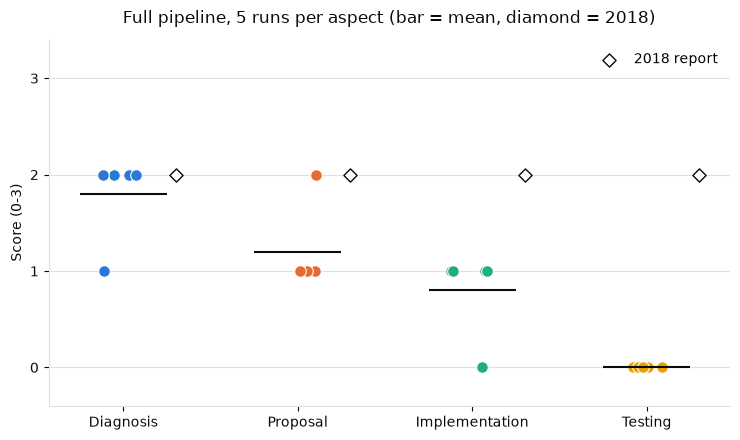

In [12]:
rng = np.random.default_rng(0)
fig, ax = plt.subplots(figsize=(7.5, 4.5))
for i, a in enumerate(ASPECTS):
    v = scores.loc[scores["aspect"] == a, "score"].to_numpy()
    ax.scatter(np.full(len(v), i) + rng.uniform(-0.12, 0.12, len(v)), v, color=aspect_colors[a], s=70, edgecolor="white", linewidth=0.8, zorder=3)
    ax.hlines(v.mean(), i - 0.25, i + 0.25, color=ink, linewidth=1.5, zorder=4)
    ax.scatter([i + 0.3], [SCORE_2018[a]], marker="D", color="white", edgecolor=ink, s=45, zorder=5, label="2018 report" if i == 0 else None)
ax.set_xticks(range(4)); ax.set_xticklabels([a.capitalize() for a in ASPECTS], color=ink)
ax.set_yticks(range(4)); ax.set_ylim(-0.4, 3.4); ax.set_ylabel("Score (0-3)", color=ink)
ax.set_title(f"Full pipeline, {N_RUNS} runs per aspect (bar = mean, diamond = 2018)", color=ink, pad=12)
ax.legend(frameon=False, loc="upper right"); style(ax); fig.tight_layout(); plt.show()

### Where do scores come from: the core means

The score is the rounded mean of the core themes' levels, so a score flips when the mean crosses a boundary (x.5 rounds down).
`core_mean` is that mean before rounding. A run whose mean sits near a half is on the edge.

In [13]:
cm = scores[scores.aspect.isin(CORE_ASPECTS)].pivot(index="run", columns="aspect", values="core_mean")[CORE_ASPECTS]
display(cm.round(2))
print("core_mean SD by aspect:", cm.std().round(2).to_dict(), "| distance of each mean from the nearest x.5 boundary:")
display((cm.apply(lambda col: (col % 1 - 0.5).abs())).round(2))
th = {}
for r, d in RUNS.items():
    for a in CORE_ASPECTS:
        s = json.loads((d / a / "scoring.json").read_text())
        th.setdefault(a, {})[r] = "; ".join(f"{t['theme'][:32]} [{t['score']}]" for t in s.get("theme_scores", []) if t.get("score") is not None)
pd.DataFrame(th)

aspect,diagnosis,proposal,implementation
run,,,
run1,1.75,1.50,1.00
run2,2.25,1.00,1.00
run3,1.50,1.50,1.00
run4,2.00,1.25,0.75
run5,1.75,2.00,0.50


core_mean SD by aspect: {'diagnosis': 0.29, 'proposal': 0.37, 'implementation': 0.22} | distance of each mean from the nearest x.5 boundary:


aspect,diagnosis,proposal,implementation
run,,,
run1,0.25,0.00,0.50
run2,0.25,0.50,0.50
run3,0.00,0.00,0.50
run4,0.50,0.25,0.25
run5,0.25,0.50,0.00


,diagnosis,proposal,implementation
run1,"High, opaque and variable tenant [2]; Principal-agent market failure [1]; Existing regulation has not fixe...",Rebalancing market power through [1]; Scottish precedent as the eviden [3]; Scope and design of the ban [0...,Local authority (Trading Standar [1]; Tenant empowerment and education [1]; Additional enforcement mechani...
run2,High and opaque tenant fees [3]; Market failure from misaligned i [2]; Existing transparency regulation [2...,Rebalancing market power toward [0]; Scope and design of the ban [1]; Scottish precedent as supporting [3...,Local authority enforcement via [1]; Additional enforcement infrastru [1]; Tenant empowerment and educati...
run3,Scale and variability of tenant [2]; Weak tenant market power and mis [1]; Failure of existing transparen...,Banning fees to rebalance market [1]; Scope and exceptions of the ban [0]; Scottish precedent as supportin...,Local authority (Trading Standar [1]; Potential lead enforcement autho [1]; Tenant empowerment and educati...
run4,High and opaque tenant fees [3]; Tenants' lack of market power [1]; Financial harm to tenants [2],Rebalancing market power through [0]; Scottish precedent as supporting [3]; Assessing the rent/cost trade-...,Local enforcement via Trading St [1]; Penalties for non-compliance [1]; Tenant empowerment and education [...
run5,High and opaque tenant fees [2]; Weak tenant market power [1]; Failure of existing transparency [2]; Finan...,Shifting costs to the landlord m [3]; Benefits to tenants from a clear [1]; Comprehensive scope to prevent...,Local authority enforcement [0]; Strengthened enforcement archite [1]; Tenant empowerment and education [0...


### Where the score changed: what did the reasoning say?

For each aspect that did not give the same score in every run, one example reasoning per distinct score.

In [14]:
unstable_aspects = summ.index[~summ["same in every run"]].tolist()
if not unstable_aspects:
    print(f"Every aspect gave the same score in all {N_RUNS} runs - nothing to inspect.")
for a in unstable_aspects:
    print(f"=== {a} (scores: {summ.loc[a, 'scores_seen']}) ===\n")
    sub = scores[scores.aspect == a].sort_values("score")
    for sv, g in sub.groupby("score"):
        ex = g.iloc[0]; print(f"--- score {sv} (run {ex['run']}, runs with this score: {len(g)}) ---"); print(ex["reasoning"][:1100]); print()

=== diagnosis (scores: [1, 2]) ===

--- score 1 (run run3, runs with this score: 1) ---
The diagnosis section is built on four core themes. 'Scale and variability of tenant fees' reaches level 2: DCLG's own agent survey is described methodologically and is reinforced by cited external data (NALS/ARLA Ref 3, Generation Rent Ref 4/6, Shelter Ref 5) showing fee ranges (£30-£780) and median/mean figures, clearly linked to the claim of high, variable fees. 'Financial and behavioural harm to tenants' also reaches level 2, citing EHS 2014-15 (60% median rise) and Citizens Advice (Ref 13: 64% had problems paying, 42% borrowed), directly linked to the harm claim. By contrast, 'Weak tenant market power' stays at level 1: the only evidence, the OFT 2013 market study, is named in prose but never given a reference number or link, so a reader cannot trace it; the rest is argument about incentives, not evidence. 'Failure of existing transparency requirements' also sits at level 1: only the NLA survey

### Fixed extraction against varying extraction

`results/letting_agent_fees/stability/find_core_run{1..3}` repeated core-theme finding, grouping and scoring three times on a **single** extraction
(one older extraction call, 30 September). Comparing their spread with the five full runs shows how much extraction adds on top of the
downstream noise (the same comparison `scoring_reproducibility.ipynb` made for the scoring call alone).

,diagnosis,proposal,implementation,testing,total
fixed1,2,2,1,0,5
fixed2,2,2,0,0,4
fixed3,2,2,1,0,5


,fixed extraction (3 runs): scores seen,fixed extraction: SD,full pipeline (5 runs): scores seen,full pipeline: SD
diagnosis,[2],0.00,"[1, 2]",0.45
proposal,[2],0.00,"[1, 2]",0.45
implementation,"[0, 1]",0.58,"[0, 1]",0.45
testing,[0],0.00,[0],0.00


Total score: fixed-extraction range 4-5 (SD 0.58); full pipeline range 3-4 (SD 0.45)


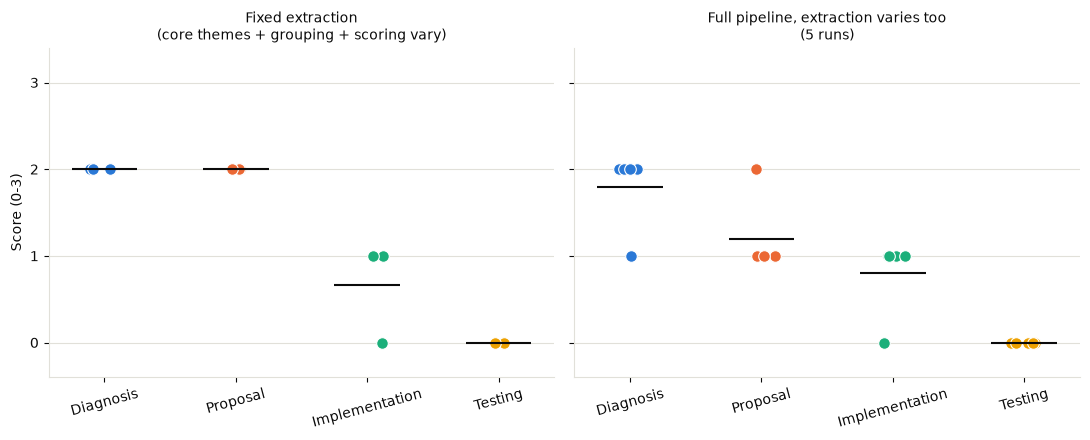

In [15]:
fixed = {}
for n in (1, 2, 3):
    d = RESULTS / DOC / "stability" / f"find_core_run{n}"
    fixed[f"fixed{n}"] = {a: (json.loads((d / a / "scoring.json").read_text())["score"] if (d / a / "scoring.json").exists() else None) for a in ASPECTS}
fixed = pd.DataFrame(fixed).T
fixed["total"] = fixed[ASPECTS].sum(axis=1)
display(fixed)
cmp = pd.DataFrame({"fixed extraction (3 runs): scores seen": {a: sorted(fixed[a].dropna().unique().tolist()) for a in ASPECTS},
                    "fixed extraction: SD": fixed[ASPECTS].std().round(2),
                    "full pipeline (%d runs): scores seen" % N_RUNS: summ["scores_seen"],
                    "full pipeline: SD": summ["std"].round(2)})
display(cmp)
print(f"Total score: fixed-extraction range {fixed['total'].min()}-{fixed['total'].max()} (SD {fixed['total'].std():.2f}); full pipeline range {t.min()}-{t.max()} (SD {t.std():.2f})")
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for ax, (title, df_) in zip(axes, [("Fixed extraction\n(core themes + grouping + scoring vary)", fixed[ASPECTS]),
                                  (f"Full pipeline, extraction varies too\n({N_RUNS} runs)", wide[ASPECTS])]):
    for i, a in enumerate(ASPECTS):
        v = df_[a].dropna().to_numpy(dtype=float)
        ax.scatter(np.full(len(v), i) + rng.uniform(-0.12, 0.12, len(v)), v, color=aspect_colors[a], s=70, edgecolor="white", linewidth=0.8, zorder=3)
        ax.hlines(v.mean(), i - 0.25, i + 0.25, color=ink, linewidth=1.5, zorder=4)
    ax.set_xticks(range(4)); ax.set_xticklabels([a.capitalize() for a in ASPECTS], color=ink, rotation=15); ax.set_title(title, color=ink, fontsize=10)
    ax.set_yticks(range(4)); ax.set_ylim(-0.4, 3.4); style(ax)
axes[0].set_ylabel("Score (0-3)", color=ink); fig.tight_layout(); plt.show()

### Does the score follow what was extracted?

Per run: how many sentences were extracted and how many ended up in core themes, next to the score.

In [16]:
rows = []
for r, d in RUNS.items():
    for a in ASPECTS:
        row = {"run": r, "aspect": a, "sentences extracted": len(aspect_ids(d, a)), "score": int(wide.loc[r, a])}
        if a in CORE_ASPECTS: row["core sentences"] = len(core[a][r]); row["core_mean"] = round(float(cm.loc[r, a]), 2)
        rows.append(row)
rel = pd.DataFrame(rows)
display(rel.pivot(index="run", columns="aspect", values="sentences extracted")[ASPECTS])
for a in ASPECTS:
    sub = rel[rel.aspect == a]
    if sub["score"].nunique() > 1 and sub["sentences extracted"].nunique() > 1:
        print(f"{a}: Spearman correlation of sentences extracted with score: {sub['sentences extracted'].corr(sub['score'], method='spearman'):.2f} (n={len(sub)})")

aspect,diagnosis,proposal,implementation,testing
run,,,,
run1,188,72,112,0
run2,109,58,117,0
run3,91,90,68,0
run4,92,60,74,0
run5,234,76,71,0


diagnosis: Spearman correlation of sentences extracted with score: 0.71 (n=5)
proposal: Spearman correlation of sentences extracted with score: 0.35 (n=5)
implementation: Spearman correlation of sentences extracted with score: 0.35 (n=5)


### Extraction stability of the sentences that feed the scores

A score is built only from the **core sentences**: those that the grouping step places in a core theme. So the question that matters for scoring is not how stable extraction is overall (above) but how stable it is for the sentences that end up core. A core sentence can be missing from another run in two ways: it was **not extracted** for that aspect at all (step 1), or it was extracted but **not placed in a core theme** (steps 2-3, which depend on the themes named).

First, for every sentence that is core in at least one run, how many of the five runs extracted it into the aspect, set against sentences that were extracted but never core. Fisher's exact test compares the share extracted by all five runs in the two groups.

In [17]:
from scipy.stats import fisher_exact
ext_n = {a: calls[a].sum(axis=1) for a in CORE_ASPECTS}          # number of runs that extracted each sentence into the aspect
rows = []
for a in CORE_ASPECTS:
    anycore = core_var[a] > 0
    ext = ext_n[a]
    c, n = ext[anycore], ext[(ext > 0) & ~anycore]
    _, p = fisher_exact([[int((c == N_RUNS).sum()), int((c < N_RUNS).sum())], [int((n == N_RUNS).sum()), int((n < N_RUNS).sum())]])
    rows.append({"aspect": a, "core in any run": len(c), "extracted by all runs": int((c == N_RUNS).sum()),
                 "% by all": round(100 * (c == N_RUNS).mean()), "extracted by 2 or fewer runs": int((c <= 2).sum()),
                 "extracted, never core": len(n), "of which by all runs": int((n == N_RUNS).sum()),
                 "% by all (never core)": round(100 * (n == N_RUNS).mean()), "Fisher p": float(f"{p:.2g}")})
support_tab = pd.DataFrame(rows).set_index("aspect")
support_tab

,core in any run,extracted by all runs,% by all,extracted by 2 or fewer runs,"extracted, never core",of which by all runs,% by all (never core),Fisher p
aspect,,,,,,,,
diagnosis,83,56,67,17,151,28,19,1.500000e-13
proposal,58,44,76,8,57,3,5,8.300000e-16
implementation,117,57,49,46,12,1,8,1.200000e-02


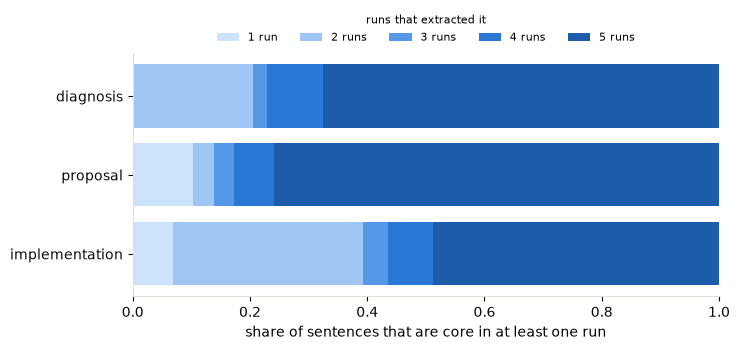

In [18]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
left = np.zeros(len(CORE_ASPECTS))
for k in range(1, N_RUNS + 1):
    frac = np.array([(ext_n[a][core_var[a] > 0] == k).mean() for a in CORE_ASPECTS])
    ax.barh(CORE_ASPECTS, frac, left=left, color=blue_ramp[k - 1], label=f"{k} run" + ("s" if k > 1 else ""))
    left += frac
ax.set_xlabel("share of sentences that are core in at least one run"); ax.set_xlim(0, 1); ax.invert_yaxis()
ax.legend(title="runs that extracted it", ncol=5, frameon=False, loc="lower center", bbox_to_anchor=(0.5, 1.0), fontsize=8, title_fontsize=8)
style(ax, ygrid=False); plt.tight_layout(); plt.show()

Second, where the disagreement on core membership comes from. Take every ordered pair of runs (x, y) and each sentence that is core in x. Either it is also core in y, or it was not extracted by y, or y extracted it but placed it outside the core themes. The last two shares say whether a run-to-run change in the core comes from extraction or from the theme and grouping steps.

In [19]:
rows = []
for a in CORE_ASPECTS:
    stay = lost_ext = lost_grp = 0
    for x in RUNS:
        for y in RUNS:
            if x == y: continue
            ey = aspect_ids(RUNS[y], a)
            for i in core[a][x]:
                if i in core[a][y]: stay += 1
                elif i in ey: lost_grp += 1
                else: lost_ext += 1
    n = stay + lost_ext + lost_grp
    rows.append({"aspect": a, "core sentence, other run": n, "also core": round(stay / n, 3), "not extracted": round(lost_ext / n, 3),
                 "extracted, not core": round(lost_grp / n, 3), "share of losses from extraction": round(lost_ext / (lost_ext + lost_grp), 2)})
pd.DataFrame(rows).set_index("aspect")

,"core sentence, other run",also core,not extracted,"extracted, not core",share of losses from extraction
aspect,,,,,
diagnosis,1268,0.845,0.107,0.047,0.69
proposal,828,0.800,0.068,0.133,0.34
implementation,1264,0.706,0.157,0.138,0.53


Third, per run: how much of each run's core rests on sentences that every run extracted (robust) and how much on sentences that two runs or fewer extracted (fragile), next to the score.

In [20]:
rows = []
for r in RUNS:
    for a in CORE_ASPECTS:
        c = core[a][r]; e = ext_n[a]
        rows.append({"run": r, "aspect": a, "core sentences": len(c), "robust (all runs extracted)": sum(e[i] == N_RUNS for i in c),
                     "fragile (2 or fewer)": sum(e[i] <= 2 for i in c),
                     "% robust": round(100 * np.mean([e[i] == N_RUNS for i in c])), "score": int(wide.loc[r, a]), "core_mean": round(float(cm.loc[r, a]), 2)})
robust = pd.DataFrame(rows)
for a in CORE_ASPECTS: display(robust[robust.aspect == a].drop(columns="aspect").set_index("run").rename_axis(a))

,core sentences,robust (all runs extracted),fragile (2 or fewer),% robust,score,core_mean
diagnosis,,,,,,
run1,60,48,4,80,2,1.75
run2,72,51,13,71,2,2.25
run3,60,54,0,90,1,1.50
run4,54,51,0,94,2,2.00
run5,71,47,17,66,2,1.75


,core sentences,robust (all runs extracted),fragile (2 or fewer),% robust,score,core_mean
proposal,,,,,,
run1,39,34,2,87,1,1.50
run2,52,44,4,85,1,1.00
run3,40,31,4,78,1,1.50
run4,37,32,0,86,1,1.25
run5,39,39,0,100,2,2.00


,core sentences,robust (all runs extracted),fragile (2 or fewer),% robust,score,core_mean
implementation,,,,,,
run1,54,46,6,85,1,1.00
run2,98,47,42,48,1,1.00
run3,45,44,0,98,1,1.00
run4,64,57,0,89,1,0.75
run5,55,46,4,84,0,0.50


## 3b. Nested design: repeating the downstream steps on each extraction

The five full runs vary extraction and everything after it together. To separate the two, the later steps (core-theme finding, grouping, scoring) were
repeated **twice more on each of the five extractions**, with the extraction held fixed (`scripts/stability_runs.py find_core`, `find_core_grouping`,
`find_core_score`; results in `results/letting_agent_fees_rep{n}/stability/find_core_run{1,2}`). Together with the original live run on that extraction, this
gives 5 extractions x 3 downstream repeats = 15 scores per aspect. A one-way random-effects ANOVA then splits the variance of each score into a component
between extractions and a component within an extraction (downstream noise); the extraction share is the ICC(1).

In [21]:
REPS = list(RUNS.values())
repeat_dirs = [[d, d / "stability" / "find_core_run1", d / "stability" / "find_core_run2"] for d in REPS]
assert all((x / "diagnosis" / "scoring.json").exists() for g in repeat_dirs for x in g), "nested repeats missing"

def score_in(d, a):
    p = d / a / "scoring.json"
    return json.loads(p.read_text())["score"] if p.exists() else 0

S = {a: np.array([[score_in(x, a) for x in g] for g in repeat_dirs], float) for a in ASPECTS}   # extraction x repeat
S["total"] = sum(S[a] for a in ASPECTS)
tot = pd.DataFrame(S["total"].astype(int), index=[f"extraction {i+1} ({sum(len(aspect_ids(d, a)) for a in CORE_ASPECTS)} sentences)" for i, d in enumerate(REPS)],
                   columns=["live run", "repeat 1", "repeat 2"])
display(tot)
per = pd.DataFrame({a: ["/".join(str(int(S[a][e, r])) for r in range(3)) for e in range(len(REPS))] for a in CORE_ASPECTS}, index=tot.index)
display(per.rename_axis("scores (live / repeat 1 / repeat 2)"))

,live run,repeat 1,repeat 2
extraction 1 (372 sentences),4,5,4
extraction 2 (284 sentences),4,4,3
extraction 3 (249 sentences),3,4,2
extraction 4 (226 sentences),4,4,5
extraction 5 (381 sentences),4,3,4


,diagnosis,proposal,implementation
scores (live / repeat 1 / repeat 2),,,
extraction 1 (372 sentences),2/2/2,1/2/1,1/1/1
extraction 2 (284 sentences),2/2/1,1/1/1,1/1/1
extraction 3 (249 sentences),1/2/1,1/1/1,1/1/0
extraction 4 (226 sentences),2/2/2,1/1/2,1/1/1
extraction 5 (381 sentences),2/1/2,2/2/2,0/0/0


In [22]:
def components(X):
    n, k = X.shape
    msb = k * X.mean(1).var(ddof=1); msw = X.var(axis=1, ddof=1).mean()
    sb = max((msb - msw) / k, 0.0)
    return sb, msw, (sb / (sb + msw) if sb + msw > 0 else np.nan)

rng = np.random.default_rng(0)
rows = []
for name in CORE_ASPECTS + ["total"]:
    X = S[name]; sb, sw, share = components(X)
    boots = [components(X[rng.integers(0, len(X), len(X))])[2] for _ in range(4000)]
    lo, hi = np.nanpercentile(boots, [2.5, 97.5])
    rows.append({"score": name, "mean": round(X.mean(), 2), "SD between extractions": round(np.sqrt(sb), 2), "SD within an extraction": round(np.sqrt(sw), 2),
                 "extraction share of variance (ICC)": round(share, 2), "95% bootstrap CI": f"{lo:.2f} to {hi:.2f}"})
pd.DataFrame(rows).set_index("score")

,mean,SD between extractions,SD within an extraction,extraction share of variance (ICC),95% bootstrap CI
score,,,,,
diagnosis,1.73,0.11,0.45,0.05,0.00 to 0.40
proposal,1.33,0.35,0.37,0.48,0.00 to 1.00
implementation,0.73,0.41,0.26,0.71,0.00 to 1.00
total,3.80,0.39,0.68,0.25,0.00 to 0.36


The bootstrap resamples the five extractions, so the intervals are wide. The point is the order of magnitude: how much of the variation in a score comes from
what was extracted and how much from re-running the later steps on the same extraction.

In [23]:
within, between = {a: [] for a in CORE_ASPECTS + ["total"]}, {a: [] for a in CORE_ASPECTS + ["total"]}
n_e, n_r = S["total"].shape
for name in within:
    X = S[name]
    for e1 in range(n_e):
        for r1 in range(n_r):
            for e2 in range(n_e):
                for r2 in range(n_r):
                    if (e1, r1) >= (e2, r2): continue
                    (within if e1 == e2 else between)[name].append((X[e1, r1], X[e2, r2]))
rows = []
for name in within:
    w, b = np.array(within[name]), np.array(between[name])
    rows.append({"score": name, "within-extraction pairs": len(w), "identical (within)": f"{np.mean(w[:,0]==w[:,1]):.0%}", "within 1 (within)": f"{np.mean(abs(w[:,0]-w[:,1])<=1):.0%}",
                 "between-extraction pairs": len(b), "identical (between)": f"{np.mean(b[:,0]==b[:,1]):.0%}", "within 1 (between)": f"{np.mean(abs(b[:,0]-b[:,1])<=1):.0%}"})
pd.DataFrame(rows).set_index("score")

,within-extraction pairs,identical (within),within 1 (within),between-extraction pairs,identical (between),within 1 (between)
score,,,,,,
diagnosis,15,60%,100%,90,58%,100%
proposal,15,73%,100%,90,49%,100%
implementation,15,87%,100%,90,53%,100%
total,15,27%,93%,90,40%,82%


### Core sentences: within an extraction against between extractions

Jaccard overlap of the sentences in core themes. Within an extraction the sentence universe is identical, so differences come only from which themes are named and
how the grouping assigns sentences; between extractions the universe itself differs as well.

In [24]:
def core_ids_in(x, a):
    w, c = x / a / "weights.json", x / a / "classification.json"
    if not (w.exists() and c.exists()): return set()
    core = {t["theme"] for t in json.loads(w.read_text())["themes"] if t["weight"] == "core"}
    return {i for t in json.loads(c.read_text())["themes"] if t["name"] in core for i in t["ids"]}

rows = []
for a in CORE_ASPECTS:
    sets = [[core_ids_in(x, a) for x in g] for g in repeat_dirs]
    jw, jb = [], []
    for e1 in range(n_e):
        for r1 in range(n_r):
            for e2 in range(n_e):
                for r2 in range(n_r):
                    if (e1, r1) >= (e2, r2): continue
                    s1, s2 = sets[e1][r1], sets[e2][r2]
                    (jw if e1 == e2 else jb).append(len(s1 & s2) / max(len(s1 | s2), 1))
    rows.append({"aspect": a, "mean Jaccard within an extraction": round(np.mean(jw), 3), "min": round(min(jw), 3),
                 "mean Jaccard between extractions": round(np.mean(jb), 3), "min ": round(min(jb), 3)})
pd.DataFrame(rows).set_index("aspect")

,mean Jaccard within an extraction,min,mean Jaccard between extractions,min
aspect,,,,
diagnosis,0.795,0.566,0.656,0.400
proposal,0.630,0.491,0.544,0.259
implementation,0.805,0.496,0.677,0.330


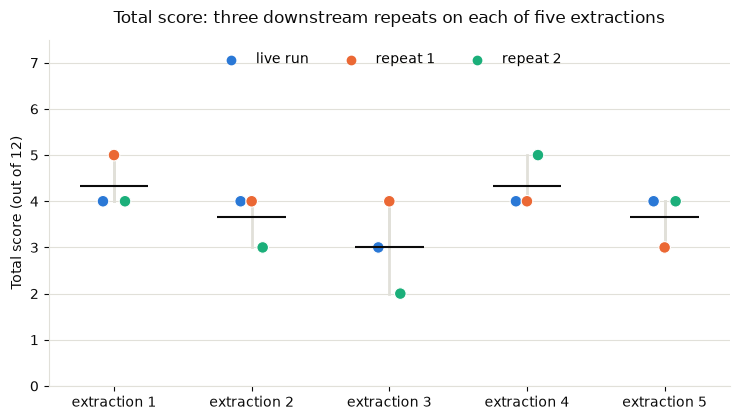

In [25]:
fig, ax = plt.subplots(figsize=(7.5, 4.3))
tot_arr = S["total"]
for e in range(n_e):
    ax.plot([e] * 3, tot_arr[e], color=grid, linewidth=2, zorder=1)
    ax.scatter([e] * 3 + np.array([-0.08, 0, 0.08]), tot_arr[e], color=["#2a78d6", "#eb6834", "#1baf7a"], s=70, edgecolor="white", linewidth=0.8, zorder=3)
    ax.hlines(tot_arr[e].mean(), e - 0.25, e + 0.25, color=ink, linewidth=1.5, zorder=4)
ax.scatter([], [], color="#2a78d6", label="live run"); ax.scatter([], [], color="#eb6834", label="repeat 1"); ax.scatter([], [], color="#1baf7a", label="repeat 2")
ax.set_xticks(range(n_e)); ax.set_xticklabels([f"extraction {i+1}" for i in range(n_e)], color=ink)
ax.set_ylabel("Total score (out of 12)", color=ink); ax.set_yticks(range(0, 8)); ax.set_ylim(0, 7.5)
ax.set_title("Total score: three downstream repeats on each of five extractions", color=ink, pad=12)
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, 1.0)); style(ax); fig.tight_layout(); plt.show()

## 4. Cost and time

In [26]:
usage = {}
for l in open("../web_app/logs/llm_usage.jsonl"):
    try: r = json.loads(l)
    except Exception: continue
    if r.get("provider") == "anthropic" and r.get("status") == "success" and r.get("policy_name") in {d.name for d in RUNS.values()}:
        u = usage.setdefault(r["policy_name"], {"cost": 0.0, "seconds": 0.0, "calls": 0}); u["cost"] += r.get("cost_usd") or 0; u["seconds"] += (r.get("duration_ms") or 0) / 1000; u["calls"] += 1
cost = pd.DataFrame(usage).T.rename_axis("run folder")
cost["cost"] = cost["cost"].round(3); cost["seconds"] = cost["seconds"].round(0)
display(cost)
print(f"Total ${cost['cost'].sum():.2f} for {len(cost)} runs; mean ${cost['cost'].mean():.2f} per run; model-call time {cost['seconds'].sum()/60:.0f} minutes in total")

,cost,seconds,calls
run folder,,,
letting_agent_fees_rep1,1.445,933.0,22.0
letting_agent_fees_rep2,1.259,785.0,22.0
letting_agent_fees_rep3,1.435,971.0,22.0
letting_agent_fees_rep4,1.236,795.0,22.0
letting_agent_fees_rep5,2.236,1562.0,23.0


Total $7.61 for 5 runs; mean $1.52 per run; model-call time 84 minutes in total


## Summary (2026-10-09)

Five complete runs of the live pipeline on letting agent fees (547 sentences), every LLM step repeated. A sixth attempt (the first try of run 5)
was truncated at the extraction step and is not included.

**Extraction**
- **Per aspect (Yes/No, five runs).** Fleiss' kappa 0.61 for diagnosis, 0.73 for proposal and 0.75 for implementation; mean pairwise Cohen's kappa 0.64
  (range 0.42-0.93), 0.73 (0.61-0.88) and 0.75 (0.60-0.92). 73%, 88% and 87% of sentences get the same call in all five runs. Testing is undefined: no run
  extracts a single testing sentence. For comparison, state pension (same extraction call, five runs) gave Fleiss' kappa 0.90, 0.79, 0.73 and 0.81. So proposal
  and implementation are about as reproducible as on state pension; diagnosis is clearly less so.
- **Diagnosis has two modes.** Sentences flagged range from 91 to 234 across runs (proposal 58-90, implementation 68-117). Runs 1 and 5 (188 and 234) read "diagnosis" broadly,
  taking in general market background, and agree with each other (all-category kappa 0.78) but less with runs 2-4 (0.55-0.67); runs 3 and 4 agree most closely (0.88).
  "Diagnosis vs none" accounts for 55% of all run-pair label disagreements.
- **All categories together.** Cohen's kappa averages 0.69 (0.55-0.88) and Fleiss' kappa is 0.68; 65% of sentences (354 of 547) get the same label in every run.

**Core themes**
- Every aspect gets 3-4 named core themes in every run (four in 14 of 15 aspect-runs). The themes recur in substance (fee level and opacity; weak tenant market power and
  misaligned incentives; failure of existing regulation; for proposals, a fee ban to rebalance the market, the Scottish precedent, scope of the ban, pass-through) but the
  wording and the fourth theme chosen vary.
- Core sentences overlap moderately: mean pairwise Jaccard 0.74 for diagnosis, 0.67 for proposal and 0.58 for implementation (minima 0.62, 0.57 and 0.33), Fleiss' kappa
  0.83, 0.78 and 0.67. Of the sentences that are core in at least one run, only 44 of 83 (diagnosis), 24 of 58 (proposal) and 37 of 117 (implementation) are core in all five.

**Extraction stability of the core sentences.** What matters for a score is the extraction of the sentences that end up in core themes, and these are much more stable than extraction overall. Of the sentences that are core in at least one run, 67% (diagnosis), 76% (proposal) and 49% (implementation) were extracted by all five runs, against 19%, 5% and 8% of sentences that were extracted but never core (Fisher's exact p = 1.5e-13, 8.3e-16 and 0.012). A sentence that is core in one run is also core in another run 85%, 80% and 71% of the time. The core is lost mostly through extraction for diagnosis (69% of losses: the other run did not extract the sentence) and implementation (53%), but mostly through the theme and grouping steps for proposal (66%: extracted, but outside a core theme). The instability is concentrated in a few runs: 42 of the 46 implementation core sentences that two or fewer runs extracted sit in run 2, whose core has 98 sentences against 45-64 elsewhere (48% robust against 84-98%), and diagnosis runs 2 and 5 (the broad readings) carry 13 and 17 fragile core sentences against 0-4 elsewhere. In these five runs the scores did not follow that: run 2's implementation score was the modal 1, so the extra fragile sentences widened the core without changing its level.

**Scores**
- Diagnosis 2, 2, 1, 2, 2; proposal 1, 1, 1, 1, 2; implementation 1, 1, 1, 1, 0; testing 0 in all five. Each aspect has a modal score in four of five runs. Only
  testing is identical in all five. Over all run pairs 70% of aspect scores are identical and 100% are within one level; the total (out of 12) is 3 or 4 in four runs
  and 4 in the fifth, mean 3.8, SD 0.45, identical in 60% of pairs and within one point in all; ICC(1,1) across aspects is 0.78.
- Where the score moves it is mostly at a rounding boundary: four of the 15 core aspect scores have a core mean of exactly x.5 (proposal 1.5 in runs 1 and 3, diagnosis 1.5
  in run 3, implementation 0.5 in run 5), and exact halves round down. Rounded up, the proposal scores would be 2, 1, 2, 1, 2 and the implementation scores all 1, giving
  totals of 5, 4, 5, 4, 5 (computed from the core means above).
- **Nested design (the later steps repeated three times on each of the five extractions, 15 scores per aspect).** The extraction share of the variance in the
  total score is about a quarter (ICC 0.25; bootstrap interval 0.00-0.36, very wide with five extractions): the standard deviation of a total is 0.39 between extractions
  and 0.68 within an extraction, so re-running core-theme finding, grouping and scoring on identical sentences moves the total more than changing the extraction does.
  By aspect it differs. Diagnosis is almost all downstream noise (extraction share 5%; SD 0.11 between, 0.45 within), even though diagnosis extraction is the least
  reproducible step. Proposal is about even (48%) and implementation is mostly extraction (71%; extraction 5 scores 0 in all three repeats, extraction 3 scores 0 once).
  Identical-score rates for pairs on the same extraction against pairs on different extractions: diagnosis 60% against 58%, proposal 73% against 49%, implementation
  87% against 53%, total 27% against 40% (totals within one point: 93% against 82%). Core-sentence overlap is higher on the same extraction (Jaccard 0.80, 0.63 and 0.81 for
  diagnosis, proposal and implementation) than across extractions (0.66, 0.54 and 0.68).
- **Against the older fixed-extraction repeats.** Three earlier repeats on one older extraction gave totals 5, 4, 5 and proposal 2 every time; the fresh runs give 3-5
  with proposal 1 or 2. That may mean the older extraction was an unusual draw, but it cannot be shown from five.

**What it means for the comparison with 2018.** 2018 scored this document 8 (2/2/2/2); the five runs score 3-4. The gap of about four points is roughly nine times the
run-to-run SD of the total, so noise in the pipeline does not explain the gap with 2018; reproducibility is adequate for ranking documents but the level is consistently lower.
The earlier 20-document comparison used the older single run (total 5) for this document, which is the high end of what this pipeline produces.

**Cost and time.** The four first-attempt runs cost $0.70-0.84 each (mean $0.77) and took 7.7-9.9 minutes. The first attempt at run 5 hit the 75,000-output-token cap
at the extraction step, was truncated and produced nothing ($0.81, 10.4 minutes); the rerun cost $0.77. The ten downstream-only repeats cost $2.96 (about $0.30 each, 70 calls, roughly 35 minutes). Total spend on this study $7.61 ($4.65 for the five full runs
including the failed attempt, plus $2.96); the cost table in section 4 totals every call charged to each run folder, so it includes both. One truncation in six extraction calls on this document is itself a reliability finding: the extraction output cap can be reached.

Caveats: one document and five runs; core themes are compared through their sentences, not matched by name automatically; kappa for testing cannot be computed
because nothing is extracted; the 2018 scores are not ground truth.